# Program 36: Stock Prices Closing Variability Metrics

**Scenario / Problem Statement**

Analyze stock records to calculate closing-price standard deviation, price range, and daily returns.

Run the cells from top to bottom in Google Colab.

## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 2. Load data and perform the analysis

Dataset loaded: FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q36_Stock_Prices.csv
Dataset shape: (60, 6)
Stock Prices Analysis:
Standard Deviation (Volatility metric): 5.01
Total range of stock movement: $23.33
Average daily return: 0.028%


,Date,Open,High,Low,Close,Volume
0,2026-01-02,$147.19,$149.21,$145.03,$147.62,"1,701,793"
1,2026-01-05,$153.23,$154.39,$151.86,$152.44,"1,526,284"
2,2026-01-06,$154.00,$156.96,$153.23,$155.18,"3,030,314"
3,2026-01-07,$152.51,$156.67,$150.49,$154.70,"3,118,837"
4,2026-01-08,$157.70,$158.67,$155.48,$158.05,"1,468,508"


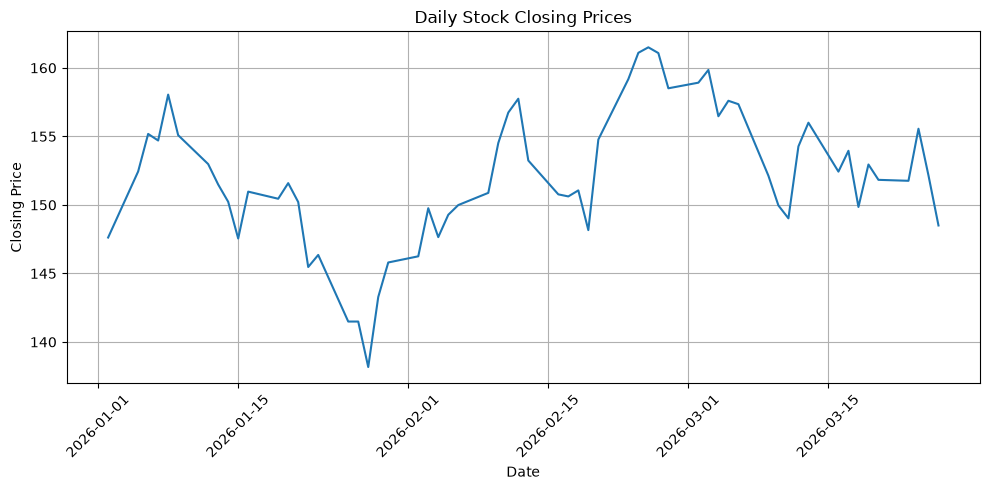

In [2]:
# Load the supplied CSV. In Colab, upload it if it is not already present.
from pathlib import Path
DATA_FILE = 'FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q36_Stock_Prices.csv'
if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError('FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q36_Stock_Prices.csv is missing; place the CSV beside this notebook.') from exc
df_raw = pd.read_csv(DATA_FILE, skiprows=3)
print("Dataset loaded:", DATA_FILE)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())

df_raw["Close"] = pd.to_numeric(df_raw["Close"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False), errors="coerce")
df_raw["Date"] = pd.to_datetime(df_raw["Date"], errors="coerce")
df_stock = df_raw.dropna(subset=["Date", "Close"]).sort_values("Date").copy()

std_dev = df_stock["Close"].std()
price_range = df_stock["Close"].max() - df_stock["Close"].min()
df_stock["Daily_Return_%"] = df_stock["Close"].pct_change() * 100

print("Stock Prices Analysis:")
print(f"Standard Deviation (Volatility metric): {std_dev:.2f}")
print(f"Total range of stock movement: ${price_range:.2f}")
print(f"Average daily return: {df_stock['Daily_Return_%'].mean():.3f}%")

plt.figure(figsize=(10, 5))
plt.plot(df_stock["Date"], df_stock["Close"])
plt.title("Daily Stock Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 3. Result

The output above displays the required analysis, model results, or visualization.